# 01 — Exploración: ventas de vehículos eléctricos

Cuaderno para mirar el conjunto de `data/` y decidir qué entrenar después. Aquí se prototipa. El entrenamiento que queda registrado en MLflow vive en `src/train.py`, no en este archivo.

**Dataset:** *EV SALE GLOBALLY 2010 - 2025 | FORECASTING 2035* (Kaggle, ahsan442002), archivo `EV data by country 2026.csv`: 49 375 filas × 9 columnas.

**Pregunta:** ¿cuántos vehículos eléctricos se venden en un país, en un año, según el tipo de vehículo (`mode`) y el tipo de motor (`powertrain`)? Es un problema de **regresión**: el objetivo `value` es un número, no una clase.

In [1]:
import pandas as pd # manejo de datos
import numpy as np
import matplotlib.pyplot as plt # graficos
from sklearn.model_selection import train_test_split # division de datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler, OneHotEncoder # preprocesamiento de datos
# importar modelos de regresion
from sklearn.linear_model import LinearRegression # regresion lineal
from sklearn.svm import SVR # maquinas de soporte vectorial para regresion
from sklearn.tree import DecisionTreeRegressor # arbol de decision
from sklearn.ensemble import RandomForestRegressor # random forest
from sklearn.compose import TransformedTargetRegressor # entrenar sobre log(ventas)
# importar metricas de regresion
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
ruta_datos = "../data/EV_data_by_country_2026.csv"
df_ev = pd.read_csv(ruta_datos)
df_ev.head(3)

,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
0,Chile,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,1.0,Other
1,Norway,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,18.0,Other
2,Portugal,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,6.0,Other


In [3]:
df_ev.info()

<class 'pandas.DataFrame'>
RangeIndex: 49375 entries, 0 to 49374
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   region_country   48297 non-null  str    
 1   category         49375 non-null  str    
 2   parameter        49375 non-null  str    
 3   mode             49375 non-null  str    
 4   powertrain       49375 non-null  str    
 5   year             49375 non-null  int64  
 6   unit             26793 non-null  str    
 7   value            49375 non-null  float64
 8   Aggregate group  49375 non-null  str    
dtypes: float64(1), int64(1), str(7)
memory usage: 6.2 MB


## Qué hay en el archivo

El archivo mezcla muchos indicadores en formato largo: la columna `parameter` dice qué se midió (ventas, stock, cargadores, precios...) y `unit` en qué unidad. También mezcla países con regiones agregadas (`World`, `European Union`, `Advanced Economies`...) y datos históricos con proyecciones.

In [4]:
for columna in ["category", "parameter", "Aggregate group", "powertrain", "unit"]:
    print(df_ev[columna].value_counts(dropna=False).head(8), "\n")

category
Historical          48114
Projection-STEPS      640
Projection-CPS        621
Name: count, dtype: int64 

parameter
EV stock              7891
EV sales              7647
price_p0_2025USD      3226
price_p100_2025USD    3226
price_p25_2025USD     3226
price_p50_2025USD     3226
price_p75_2025USD     3226
price_p95_2025USD     3226
Name: count, dtype: int64 

Aggregate group
Other                 31729
Projection_country     9846
Projection_region      2955
Other_aggregate        2844
_World                 1230
European Union          771
Name: count, dtype: int64 

powertrain
EV                         15416
BEV                        11584
ICEV                        9268
PHEV                        7773
FCEV                        1623
ALL                         1568
EREV                         686
Publicly available slow      580
Name: count, dtype: int64 

unit
NaN                                   22582
Vehicles                              15538
percent                

## Filtros

- Solo `category = Historical` (las proyecciones STEPS/CPS son escenarios, no datos observados).
- Solo `parameter = EV sales` en `unit = Vehicles`.
- Solo países: `Aggregate group` en `Other` o `Projection_country` (este último incluye a China, USA, India, Japón y Corea con sus datos históricos). Fuera `World`, `European Union` y los agregados, porque repiten la suma de los países.
- Fuera `powertrain = EV`, que es la suma de BEV + PHEV.

In [5]:
df_ev = df_ev[(df_ev["category"] == "Historical") & (df_ev["parameter"] == "EV sales") & (df_ev["unit"] == "Vehicles")]
df_ev = df_ev[df_ev["Aggregate group"].isin(["Other", "Projection_country"])]
df_ev = df_ev[df_ev["powertrain"] != "EV"]
# columnas que quedaron constantes
df_ev = df_ev.drop(columns=["category", "parameter", "unit", "Aggregate group"])
df_ev = df_ev.drop_duplicates().dropna()
df_ev = df_ev[df_ev["value"] >= 1]
df_ev.info()

<class 'pandas.DataFrame'>
Index: 3309 entries, 915 to 18904
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   region_country  3309 non-null   str    
 1   mode            3309 non-null   str    
 2   powertrain      3309 non-null   str    
 3   year            3309 non-null   int64  
 4   value           3309 non-null   float64
dtypes: float64(1), int64(1), str(3)
memory usage: 211.4 KB


In [6]:
print("Países:", df_ev["region_country"].nunique(), "| Años:", df_ev["year"].min(), "-", df_ev["year"].max())
df_ev["value"].describe()

Países: 61 | Años: 2010 - 2025


count    3.309000e+03
mean     5.108228e+04
std      4.751358e+05
min      1.000000e+00
25%      4.400000e+01
50%      5.000000e+02
75%      4.300000e+03
max      1.100000e+07
Name: value, dtype: float64

Las ventas van de 1 a millones de vehículos (China). Una distribución así de sesgada se modela mejor en escala logarítmica: los modelos aprenden sobre `log(1 + ventas)` y devuelven vehículos.

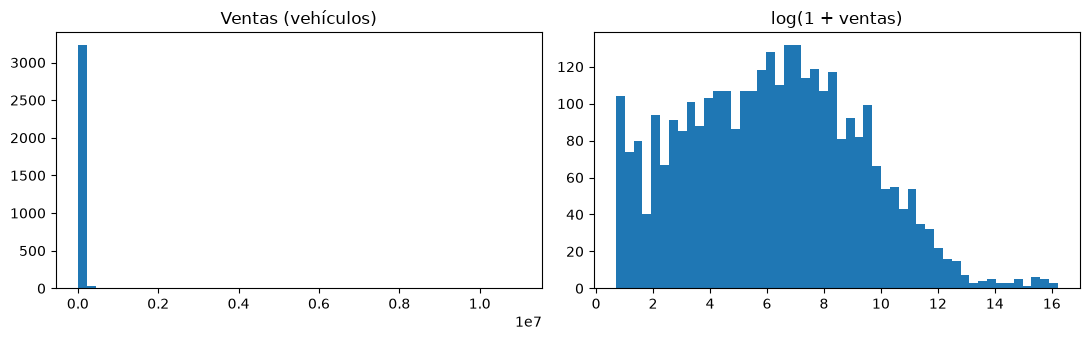

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].hist(df_ev["value"], bins=50); ejes[0].set_title("Ventas (vehículos)")
ejes[1].hist(np.log1p(df_ev["value"]), bins=50); ejes[1].set_title("log(1 + ventas)")
plt.tight_layout(); plt.show()

In [8]:
# Carros eléctricos (BEV) vendidos en Colombia
df_ev[(df_ev["region_country"] == "Colombia") & (df_ev["mode"] == "Cars") & (df_ev["powertrain"] == "BEV")][["year", "value"]]

,year,value
1709,2011,1.0
1734,2012,26.0
1763,2013,22.0
1793,2014,27.0
1822,2015,39.0
1853,2016,28.0
1885,2017,92.0
1920,2018,250.0
1956,2019,760.0
1993,2020,670.0


## Preprocesamiento

`region_country`, `mode` y `powertrain` son texto. Con `LabelEncoder` cada país quedaría como un número (China = 8, Colombia = 9) y el modelo creería que Colombia "está cerca" de China. Por eso se usa `OneHotEncoder`: una columna 0/1 por cada país, modo y powertrain. `year` se escala con `StandardScaler`.

In [9]:
columnas_texto = ["region_country", "mode", "powertrain"]
columnas_numericas = ["year"]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_texto = pd.DataFrame(encoder.fit_transform(df_ev[columnas_texto]), columns=encoder.get_feature_names_out(columnas_texto), index=df_ev.index)

scaler = StandardScaler()
X_num = pd.DataFrame(scaler.fit_transform(df_ev[columnas_numericas]), columns=columnas_numericas, index=df_ev.index)

X = pd.concat([X_texto, X_num], axis=1)
y = df_ev["value"]
print("Features:", X.shape[1])

Features: 70


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Tamaño X_train: ", X_train.shape)
print("Tamaño X_test: ", X_test.shape)

Tamaño X_train:  (2316, 70)
Tamaño X_test:  (993, 70)


In [11]:
# Definir estrategias. Cada una aprende sobre log(1 + ventas) y predice vehículos.
def en_log(modelo):
    return TransformedTargetRegressor(regressor=modelo, func=np.log1p, inverse_func=np.expm1)

modelos = {
    "Regresion lineal": en_log(LinearRegression()),
    "SVR": en_log(SVR()),
    "Arbol de decision": en_log(DecisionTreeRegressor(random_state=42)),
    "Random forest": en_log(RandomForestRegressor(random_state=42)),
}
for modelo in modelos.values():
    modelo.fit(X_train, y_train)

In [12]:
# Metricas para decidir que estrategia es mejor
resultados = []
for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)
    resultados.append({
        "modelo": nombre,
        "r2": r2_score(y_test, pred),
        "r2_log": r2_score(np.log1p(y_test), np.log1p(np.clip(pred, 0, None))),
        "mae": mean_absolute_error(y_test, pred),
        "rmse": np.sqrt(mean_squared_error(y_test, pred)),
    })
pd.DataFrame(resultados).sort_values("r2", ascending=False)

,modelo,r2,r2_log,mae,rmse
2,Arbol de decision,0.957215,0.803889,17478.495468,135685.327837
3,Random forest,0.795783,0.872010,31374.592773,296436.302630
0,Regresion lineal,0.322413,0.700140,57807.481866,539967.516886
1,SVR,0.148504,0.817500,63172.616521,605308.136980


## Qué queda decidido para `src/`

- **Objetivo:** `value` (vehículos vendidos). **Features:** `region_country`, `mode`, `powertrain`, `year`.
- **Métrica para escoger el mejor run:** `r2` (también se guardan `r2_log`, `mae` y `rmse`). `r2` pesa más los países grandes; `r2_log` mide qué tan bien se acierta el orden de magnitud en todos los países.
- **Límites:** solo datos históricos hasta 2025; un país que no esté en el entrenamiento no se puede predecir bien (OneHotEncoder lo deja en ceros).